In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original dataset
df = pd.read_csv("Data/raw_data/train.csv")

# Convert date column
df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## Aggregate sales by store, family and date

Unlike our previous model, which combined sales across all stores for each product family, this dataset preserves sales for each individual store and product family.

For example, we can now forecast BEVERAGES sales separately for Store 1, Store 2, Store 3, and so on.

In [3]:
# Create store-level daily sales data

store_daily_data = df.groupby(
    ["date", "store_nbr", "family"],
    as_index=False
).agg({
    "sales": "sum",
    "onpromotion": "sum"
})

# Sort the data
store_daily_data = store_daily_data.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# Display results
print("Store-level dataset shape:", store_daily_data.shape)

display(store_daily_data.head())

Store-level dataset shape: (3000888, 5)


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-02,1,AUTOMOTIVE,2.0,0
2,2013-01-03,1,AUTOMOTIVE,3.0,0
3,2013-01-04,1,AUTOMOTIVE,3.0,0
4,2013-01-05,1,AUTOMOTIVE,5.0,0


we'll create features separately for each store–product-family combination. This is important: Store 1's previous sales must never become Store 2's lag values.

## Feature engineering

- lag_1: Sales of the same family at the same store on the previous day.
- 
- lag_7: Sales seven days earlier.
- 
- lag_14: Sales fourteen days earlier.
- 
- rolling_mean_7: Average sales over the previous seven days.
- 
The shift(1) ensures that today's actual sales are not included in today's rolling average, helping prevent target leakage.

In [4]:
# Create a separate dataset for feature engineering
store_model_data = store_daily_data.copy()

# Define grouping columns
group_keys = ["store_nbr", "family"]

# Calendar features
store_model_data["day_of_week"] = store_model_data["date"].dt.dayofweek
store_model_data["month"] = store_model_data["date"].dt.month
store_model_data["day_of_year"] = store_model_data["date"].dt.dayofyear

# Lag features: previous sales for the same store and family
store_model_data["lag_1"] = (
    store_model_data.groupby(group_keys)["sales"].shift(1)
)

store_model_data["lag_7"] = (
    store_model_data.groupby(group_keys)["sales"].shift(7)
)

store_model_data["lag_14"] = (
    store_model_data.groupby(group_keys)["sales"].shift(14)
)

# Rolling average of the previous 7 days
store_model_data["rolling_mean_7"] = (
    store_model_data.groupby(group_keys)["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

# Remove rows with missing lag and rolling values
store_model_data = store_model_data.dropna().reset_index(drop=True)

print("Dataset shape after feature engineering:", store_model_data.shape)
display(store_model_data.head())

Dataset shape after feature engineering: (2975940, 12)


,date,store_nbr,family,sales,onpromotion,day_of_week,month,day_of_year,lag_1,lag_7,lag_14,rolling_mean_7
0,2013-01-15,1,AUTOMOTIVE,1.0,0,1,1,15,2.0,2.0,0.0,2.142857
1,2013-01-16,1,AUTOMOTIVE,1.0,0,2,1,16,1.0,2.0,2.0,2.000000
2,2013-01-17,1,AUTOMOTIVE,1.0,0,3,1,17,1.0,2.0,3.0,1.857143
3,2013-01-18,1,AUTOMOTIVE,0.0,0,4,1,18,1.0,3.0,3.0,1.714286
4,2013-01-19,1,AUTOMOTIVE,5.0,0,5,1,19,0.0,2.0,5.0,1.285714


In [5]:
# 1. Missing values
print("Missing values:")
print(store_model_data.isnull().sum())

# 2. Duplicate records
print("\nDuplicate rows:")
print(store_model_data.duplicated(
    subset=["date", "store_nbr", "family"]
).sum())

# 3. Data types
print("\nData types:")
print(store_model_data.dtypes)

# 4. Sales statistics
print("\nSales statistics:")
display(store_model_data["sales"].describe())

# 5. Number of stores and product families
print("\nNumber of stores:", store_model_data["store_nbr"].nunique())
print("Number of families:", store_model_data["family"].nunique())

Missing values:
date              0
store_nbr         0
family            0
sales             0
onpromotion       0
day_of_week       0
month             0
day_of_year       0
lag_1             0
lag_7             0
lag_14            0
rolling_mean_7    0
dtype: int64

Duplicate rows:
0

Data types:
date              datetime64[ns]
store_nbr                  int64
family                    object
sales                    float64
onpromotion                int64
day_of_week                int32
month                      int32
day_of_year                int32
lag_1                    float64
lag_7                    float64
lag_14                   float64
rolling_mean_7           float64
dtype: object

Sales statistics:


count    2.975940e+06
mean     3.591357e+02
std      1.104695e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.970000e+02
max      1.247170e+05
Name: sales, dtype: float64


Number of stores: 54
Number of families: 33


In [6]:
Q1 = store_model_data["sales"].quantile(0.25)
Q3 = store_model_data["sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = store_model_data[
    (store_model_data["sales"] < lower_limit) |
    (store_model_data["sales"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outliers:", len(outliers))
print("Outlier percentage:",
      round(len(outliers) / len(store_model_data) * 100, 2), "%")

Lower limit: -295.5
Upper limit: 492.5
Potential outliers: 443023
Outlier percentage: 14.89 %


In [7]:
# Define test period
test_start_date = (
    store_model_data["date"].max()
    - pd.Timedelta(days=29)
)

# Chronological split
train_df = store_model_data[
    store_model_data["date"] < test_start_date
].copy()

test_df = store_model_data[
    store_model_data["date"] >= test_start_date
].copy()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training shape: (2922480, 12)
Testing shape: (53460, 12)

Training period:
2013-01-15 00:00:00 to 2017-07-16 00:00:00

Testing period:
2017-07-17 00:00:00 to 2017-08-15 00:00:00


In [8]:
# One-hot encode categorical columns
train_encoded = pd.get_dummies(
    train_df,
    columns=["family", "store_nbr"],
    drop_first=True,
    dtype=np.uint8
)

test_encoded = pd.get_dummies(
    test_df,
    columns=["family", "store_nbr"],
    drop_first=True,
    dtype=np.uint8
)

# Align test columns with training columns
X_train = train_encoded.drop(columns=["date", "sales"])
X_test = test_encoded.drop(columns=["date", "sales"])

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Reduce numerical feature memory
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# Target variables
y_train = train_encoded["sales"].astype(np.float32)
y_test = test_encoded["sales"].astype(np.float32)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Number of features:", X_train.shape[1])

X_train shape: (2922480, 93)
X_test shape: (53460, 93)
y_train shape: (2922480,)
y_test shape: (53460,)
Number of features: 93


## train the store level random forest model

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Randomly sample training data
sample_size = 500_000

X_train_sample = X_train.sample(
    n=sample_size,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

print("Sample training shape:", X_train_sample.shape)

# Train Random Forest
store_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

store_rf_model.fit(X_train_sample, y_train_sample)

print("Store-level Random Forest training completed!")

Sample training shape: (500000, 93)


KeyboardInterrupt: 

In [11]:
# Smaller training sample
sample_size = 100_000

X_train_sample = X_train.sample(
    n=sample_size,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

print("Sample shape:", X_train_sample.shape)

# Smaller Random Forest
store_rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

store_rf_model.fit(X_train_sample, y_train_sample)

print("Training completed!")

Sample shape: (100000, 93)
Training completed!


## model evaluation

In [12]:
# Generate predictions
store_predictions = store_rf_model.predict(X_test)

# Calculate evaluation metrics
store_mae = mean_absolute_error(y_test, store_predictions)

store_rmse = np.sqrt(
    mean_squared_error(y_test, store_predictions)
)

store_r2 = r2_score(y_test, store_predictions)

# Display results
print("Store-Level Random Forest Performance")
print("--------------------------------------")
print("MAE:", round(store_mae, 2))
print("RMSE:", round(store_rmse, 2))
print("R2 Score:", round(store_r2, 4))

Store-Level Random Forest Performance
--------------------------------------
MAE: 67.63
RMSE: 232.18
R2 Score: 0.9662


## compare actual vs predicted values

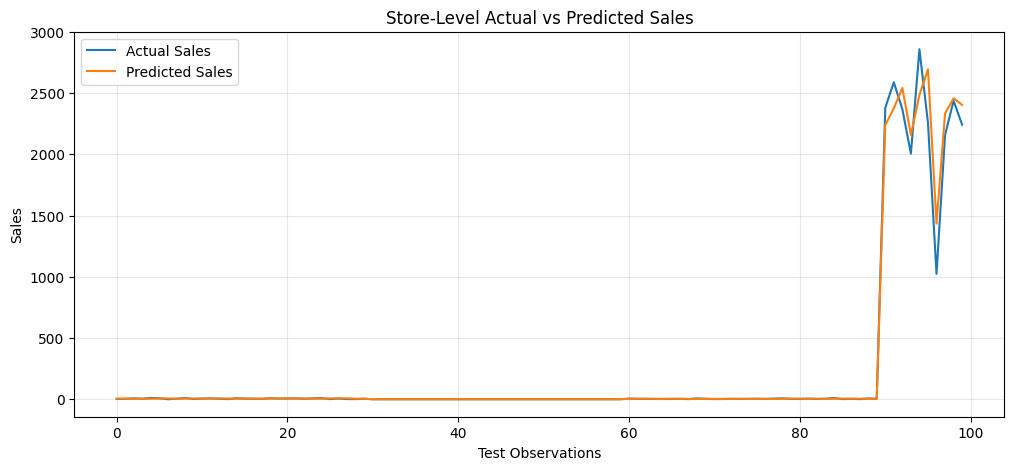

In [13]:
# Create comparison dataframe
store_results = pd.DataFrame({
    "actual_sales": y_test.values,
    "predicted_sales": store_predictions
})

# Compare the first 100 observations
plt.figure(figsize=(12, 5))

plt.plot(
    store_results["actual_sales"].values[:100],
    label="Actual Sales"
)

plt.plot(
    store_results["predicted_sales"].values[:100],
    label="Predicted Sales"
)

plt.title("Store-Level Actual vs Predicted Sales")
plt.xlabel("Test Observations")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

,feature,importance
7,rolling_mean_7,0.453562
5,lag_7,0.337771
6,lag_14,0.125200
4,lag_1,0.056956
19,family_GROCERY I,0.006422
3,day_of_year,0.005896
1,day_of_week,0.004415
0,onpromotion,0.003117
2,month,0.002001
40,store_nbr_2,0.000543


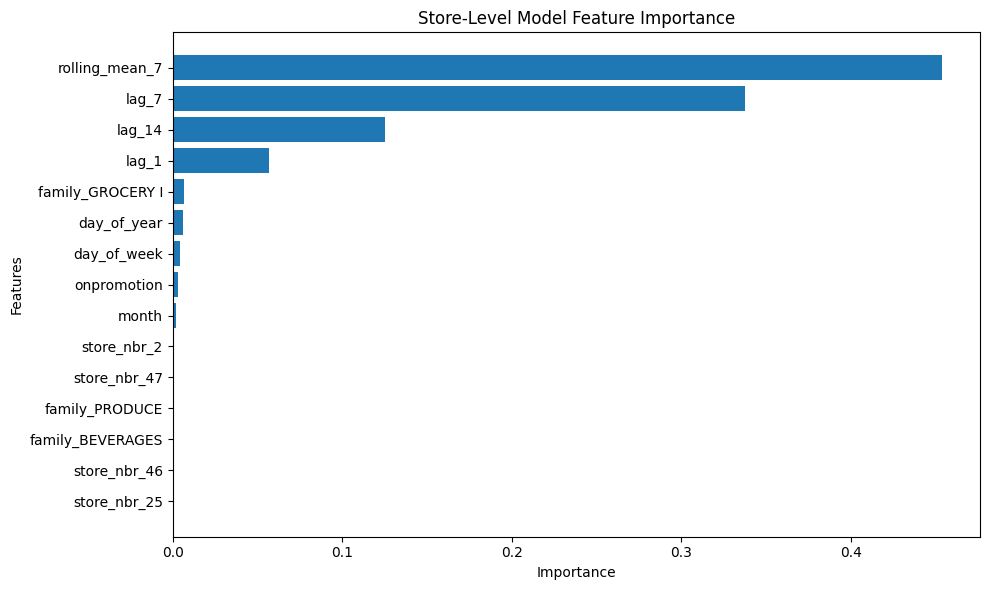

In [14]:
# Get feature importance
store_importance = pd.DataFrame({
    "feature": X_train_sample.columns,
    "importance": store_rf_model.feature_importances_
})

store_importance = store_importance.sort_values(
    by="importance",
    ascending=False
)

# Display top 15 features
display(store_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    store_importance.head(15)["feature"][::-1],
    store_importance.head(15)["importance"][::-1]
)

plt.title("Store-Level Model Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [15]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save store-level model
joblib.dump(
    store_rf_model,
    "models/store_level_random_forest.pkl"
)

# Save feature names in the correct order
joblib.dump(
    list(X_train.columns),
    "models/store_level_model_features.pkl"
)

print("Store-level model saved successfully!")

Store-level model saved successfully!


## generating 7 day forecast for storelevel data

In [16]:
# Create a separate copy of historical store-level data
store_history = store_daily_data.copy()

store_history["date"] = pd.to_datetime(store_history["date"])

# Sort historical records
store_history = store_history.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# Define forecast dates
last_date = store_history["date"].max()

forecast_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

print("Last historical date:", last_date)
print("Forecast starts:", forecast_dates.min())
print("Forecast ends:", forecast_dates.max())
print("Number of forecast days:", len(forecast_dates))

Last historical date: 2017-08-15 00:00:00
Forecast starts: 2017-08-16 00:00:00
Forecast ends: 2017-08-22 00:00:00
Number of forecast days: 7


In [20]:
# Prepare historical sales lookup
sales_history = {}

for (store, family), group in store_history.groupby(
    ["store_nbr", "family"]
):
    sales_history[(store, family)] = list(group["sales"].values)

store_feature_names = joblib.load(
    "models/store_level_model_features.pkl"
)

forecast_results = []

# Generate forecasts day by day
for forecast_date in forecast_dates:

    daily_inputs = []
    daily_records = []

    for store in sorted(store_history["store_nbr"].unique()):
        for family in sorted(store_history["family"].unique()):

            history = sales_history[(store, family)]

            features = {
                "onpromotion": 0,
                "day_of_week": forecast_date.dayofweek,
                "month": forecast_date.month,
                "day_of_year": forecast_date.dayofyear,
                "lag_1": history[-1],
                "lag_7": history[-7],
                "lag_14": history[-14],
                "rolling_mean_7": np.mean(history[-7:])
            }

            row = {feature: 0 for feature in store_feature_names}
            row.update(features)

            family_column = f"family_{family}"
            store_column = f"store_nbr_{store}"

            if family_column in row:
                row[family_column] = 1

            if store_column in row:
                row[store_column] = 1

            daily_inputs.append(row)
            daily_records.append((store, family))

    # Predict all stores and families for this day together
    input_data = pd.DataFrame(
        daily_inputs,
        columns=store_feature_names
    )

    predictions = store_rf_model.predict(input_data)

    # Update history with predicted sales
    for (store, family), prediction in zip(
        daily_records, predictions
    ):
        prediction = max(0, prediction)

        forecast_results.append({
            "date": forecast_date,
            "store_nbr": store,
            "family": family,
            "predicted_sales": prediction
        })

        sales_history[(store, family)].append(prediction)

    print("Completed:", forecast_date.date())

# Create final forecast dataframe
store_forecast_df = pd.DataFrame(forecast_results)

print("Forecast shape:", store_forecast_df.shape)
display(store_forecast_df.head(10))

KeyboardInterrupt: 

In [21]:
# Select three stores
selected_stores = [1, 2, 3]

# Prepare historical sales lookup
sales_history = {}

for (store, family), group in store_history.groupby(
    ["store_nbr", "family"]
):
    sales_history[(store, family)] = list(group["sales"].values)

store_feature_names = joblib.load(
    "models/store_level_model_features.pkl"
)

forecast_results = []

for forecast_date in forecast_dates:

    daily_inputs = []
    daily_records = []

    for store in selected_stores:
        for family in sorted(store_history["family"].unique()):

            history = sales_history[(store, family)]

            row = {feature: 0 for feature in store_feature_names}

            row.update({
                "onpromotion": 0,
                "day_of_week": forecast_date.dayofweek,
                "month": forecast_date.month,
                "day_of_year": forecast_date.dayofyear,
                "lag_1": history[-1],
                "lag_7": history[-7],
                "lag_14": history[-14],
                "rolling_mean_7": np.mean(history[-7:])
            })

            family_column = f"family_{family}"
            store_column = f"store_nbr_{store}"

            if family_column in row:
                row[family_column] = 1

            if store_column in row:
                row[store_column] = 1

            daily_inputs.append(row)
            daily_records.append((store, family))

    input_data = pd.DataFrame(
        daily_inputs,
        columns=store_feature_names
    )

    predictions = store_rf_model.predict(input_data)

    for (store, family), prediction in zip(
        daily_records, predictions
    ):
        prediction = max(0, prediction)

        forecast_results.append({
            "date": forecast_date,
            "store_nbr": store,
            "family": family,
            "predicted_sales": prediction
        })

        sales_history[(store, family)].append(prediction)

    print("Completed:", forecast_date.date())

store_forecast_df = pd.DataFrame(forecast_results)

print("Forecast shape:", store_forecast_df.shape)
display(store_forecast_df.head(10))

Completed: 2017-08-16
Completed: 2017-08-17
Completed: 2017-08-18
Completed: 2017-08-19
Completed: 2017-08-20
Completed: 2017-08-21
Completed: 2017-08-22
Forecast shape: (693, 4)


,date,store_nbr,family,predicted_sales
0,2017-08-16,1,AUTOMOTIVE,3.972534
1,2017-08-16,1,BABY CARE,0.092531
2,2017-08-16,1,BEAUTY,3.891495
3,2017-08-16,1,BEVERAGES,2293.270226
4,2017-08-16,1,BOOKS,0.092531
5,2017-08-16,1,BREAD/BAKERY,380.098529
6,2017-08-16,1,CELEBRATION,9.584701
7,2017-08-16,1,CLEANING,625.390021
8,2017-08-16,1,DAIRY,741.324346
9,2017-08-16,1,DELI,129.876254


In [23]:
import os

os.makedirs("artifacts", exist_ok=True)

store_forecast_df.to_csv(
    "artifacts/store_level_forecast.csv",
    index=False
)

print("Store-level forecast saved successfully!")
print("Total predictions:", len(store_forecast_df))

Store-level forecast saved successfully!
Total predictions: 693


In [24]:
print("Number of stores:",
      store_forecast_df["store_nbr"].nunique())

print("Number of families:",
      store_forecast_df["family"].nunique())

print("Number of forecast dates:",
      store_forecast_df["date"].nunique())

print("Missing values:")
print(store_forecast_df.isnull().sum())

Number of stores: 3
Number of families: 33
Number of forecast dates: 7
Missing values:
date               0
store_nbr          0
family             0
predicted_sales    0
dtype: int64
